# LASSI - Power Efficiency

***OLLAMA API*** + ***Argo Gateway API*** Jupyter Notebook version

+ No translation
+ Source code scripts from:
https://github.com/zjin-lcf/HeCBench/tree/master/src

Power measurements: https://pypi.org/project/nvidia-ml-py/  (pynvml)

## Setup

In [1]:
import os

# Import LASSI modules
import lassi.llm_config
import lassi.pipeline # The Pipeline script calls the other LASSI libraries not imported here.
from lassi.format_colors import color
from lassi.prompt_dictionary import PromptDictionary

# Enable the autoreload extension
%load_ext autoreload

# Reload all modules imported with %aimport every time before executing subsequent code.
%autoreload 1

# We need to reload the libraries while under development
%aimport lassi.format_colors
%aimport lassi.prompt_dictionary
%aimport lassi.llm_config
%aimport lassi.llm_methods
%aimport lassi.pipeline
%aimport lassi.get_power
%aimport lassi.argostream_curl

## Code Generation Experiment - Setup + Run

_____
***STEP 1/2: Input experimental configuration parameters in the following method.***

In [2]:
def experimental_setup():
    """
    [1] ENTER APPLICATION FOLDER NAME FROM HeCBench
        >> Execution input parameters provided.

    -- matrix-rotate ["10000", "1"]
    -- jacobi [""] (none required)
    -- DNU -- mallocFree ["10000"]
    -- layout ["1"]
    -- atomicCost ["1"]
    -- dense-embedding ["10000", "8", "1"]
    -- pathfinder ["10000", "1000", "1000"]
    -- bsearch ["10000", "1"]
    -- entropy ["10000", "1024", "1"]
    -- colorwheel ["10000", "8", "1"]
    -- randomAccess ["1"]
    -- lid-driven-cavity [""]
    """
    
    app_folder_name = "lid-driven-cavity"

    
    """
    [2] SELECT THE CODE TRANSLATION MAPPING DIRECTION EXPERIMENT CONFIGURATION
    
    CUDA -- OMP -- HIP -- SYCL -- FORTRAN
    """   
    # These should be the same if *not* doing translation.
    source_lang = "CUDA"
    target_lang = "CUDA"

    test_code_first = True  # True or False
    
    # TOGGLE USE CODE KNOWLEDGE CONTEXT FOR TARGET
    use_context = True  # True or False

    # TOGGLE USE OF POWER MEASUREMENT DURING EXE
    power_measure = True  # True or False

    # TOGGLE ENERGY EFFICIENCY SELF-CORRECTION FEEDBACK
    yes_power_feedback = True  # True or False

    # ASSIGN CODE COMPILE COMMAND
    if source_lang == "CUDA":
        code_compiler = "nvcc"
        code_compiler_kwds = "-std=c++14 -Xcompiler -Wall -arch=sm_60 -O3"
        # -arch=sm_70 for aiops01 GPU (Argonne)  # -arch=sm_80 for A100s
        # -arch=sm_60 for P100
        if yes_power_feedback:
            context_knowledge_selection = "cuda_optimization_summary"
            context_fewshot_examples = "cuda_c_few_shot_examples"
        else:
            context_knowledge_selection = "cuda"
    elif source_lang == "OMP":
        # Linux_x86_64 or Linux_aarch64
        code_compiler = "g++" # "/opt/nvidia/hpc_sdk/Linux_aarch64/2024/compilers/bin/nvc++"  # 
        code_compiler_kwds = "-fopenmp -O3" # "-Wall -O3 -Minfo -mp=gpu -gpu=cc80"  # -c
        context_knowledge_selection = "omp"

    # TOGGLE EXECUTE PIPELINE
    yes_execute = True  # True / False
    if yes_execute:
        # Enter execution input parameters, if needed
        # A list of parameter string values, e.g., ["10000", "1"]
        exe_input_parameters = [""]
    else:
        exe_input_parameters = [""]

    
    """
    [3] SELECT THE LLM TO USE FOR THE CODE TRANSLATION EXPERIMENT
    """
    # SELECT A MODEL
    
    # -- FROM ARGO:
    # model = "gpt35"  # (max token = 4096)
    # model = "gpt35large"  # (max token = 16384)
    # model = "gpt4large"  # (max token = 32768)
    # model = "gpt4turbo"  # (max token = 128000)
    model = "gpto1preview"  # (max token = 128000)
    model_coder = "gpto1preview"  # (max token = 128000)
    # model = "gpto1preview"  # (max token = 128000)

    # -- FROM OLLAMA
    # model = "deepseek-r1:70b"  # (max token = 128000)
    # model_coder = "deepseek-r1:70b"  # (max token = 131072)
    # model = "dolphin3"  # (max token = 131072)
    # model = "llama3.3:latest"  # (max token = 131072)
    # model = "phi4" # (max token = 16384)
    # model_coder = "deepseek-coder-v2:16b-lite-instruct-fp16"  # (max token = 128000)
    # model_coder = "codestral:22b"  # (max token = 32768)
    # model = "qwq:latest"  # (max token = 32768)
    # model_coder = "qwen2.5-coder:32b"  # (max token = 32768)
    # model = "codestral:22b-v0.1-q8_0"  # (max token = 32768)
    # model = "wizardcoder:33b-v1.1-q8_0"  # (max token = 16384)
    # model_coder = "deepseek-coder:33b-instruct-q8_0"  # (max token = 16384)
    # model = "deepseek-coder-v2:16b-lite-instruct-fp16"  # (max token = 128000)
    # model = "deepseek-coder-v2:16b-lite-instruct-q8_0"
    # model = "phi3:14b"  # (max token = 131072)
  
    # Set maximum context token count size for selected LLM:
    num_ctx = 128000
    num_ctx_coder = 128000

    # ASSIGN LLM API SOURCE:
    if model in ["gpt35", "gpt35large", "gpt4", "gpt4large", "gpt4turbo", "gpt4o", "gpto1preview"]:
        llm_source = "argo"
    elif "GGUF" in model:
        llm_source = "lmstudio"
    else:
        llm_source = "ollama"

    """
    [4] SET ADDITIONAL PIPELINE PARAMETERS
    """
    experiment = "02test_o1p_o1p_betterpower_withcontext_fewshots"  # Assign any label for experiment name.
    display_response = True
    test_with_error = False
    generate_test_case = False

    # Unload any previously loaded LLMs in the Ollama server 
    # (clear out the memory)
    if llm_source == "ollama":
        lassi.llm_config.unload_ollama_model(model)
        lassi.llm_config.unload_ollama_model(model_coder)

    return (app_folder_name, source_lang, target_lang, model, model_coder, num_ctx, num_ctx_coder, llm_source, use_context,
            context_knowledge_selection, code_compiler, code_compiler_kwds, yes_execute, exe_input_parameters,
            experiment, display_response, test_with_error, generate_test_case, power_measure, test_code_first, yes_power_feedback)

_____
***STEP 2/2: Run the following block to implement the pipeline with the configuration parameters.***


***** EXPERIMENT CONFIGURATION SUMMARY *****

Application: lid-driven-cavity

EE Refactoring: CUDA_ee

LLM Source: argo
Model: gpto1preview
Model coder: gpto1preview
System Prompt Index: CUDA
Code file template: generated_codes/argo_gpto1preview/promptset_CUDA/lid-driven-cavity-cuda_main_ee_refactorcode_CUDA_exp02test_o1p_o1p_betterpower_withcontext_fewshots

LLM System Prompt: 

You are an expert C++/CUDA engineer. Your goal is to refactor provided CUDA C++ code for energy efficiency by reducing GPU and CPU power consumption without losing any functionality of the original code. You must also carefully read and incorporate the best practices from the provided background documents. You always surround your generated code with the three characters ```.

LLM Prompt for Code Generation: 

Carefully follow all these instructions step-by-step: 
STEP 1. Read the background knowledge and your background knowledge summaries about programming and energy-efficiency strategies. 
STEP 2. Read you

Waiting for the system to settle down...: 100%|████████████████████████████████████████████████████████| 10/10 [00:10<00:00,  1.00s/it]


Execute command: ['./lid-driven-cavity-cuda_main', '']

Problem size: 512 x 512 
Time = 0.000477, delt = 4.768372e-04, iter = 92522, res = 9.999751e-04
Time = 0.000954, delt = 4.768372e-04, iter = 88410, res = 9.999561e-04
Time = 0.001000, delt = 4.632568e-05, iter = 86674, res = 9.999808e-04

Total execution time of the iteration loop: 21.166647 (s)
GPU power data has been written to source_CUDA_gpu_power_results.csv


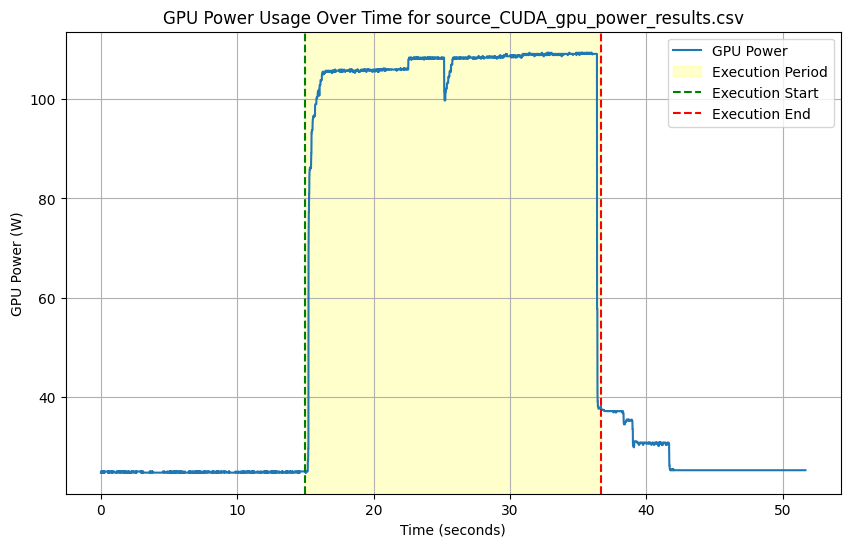

Start time: 15.0 -- End time: 36.673

Capturing idle energy consumed for same duration...
... Complete.
Code execution duration: 21.67 seconds
Total GPU energy consumption for source_CUDA_gpu_power_results.csv:
  0.000636 kWh
  0.6363 Wh
  2290.73 J
Average GPU power: 105.75 W
Total Energy During Exe Runtime:   2290.73 J
----------------------------------------------------------------------------------------------------------------------------------------

Program executed successfully!


Measure system idle power...
Duration for idle time measurement: 21.67
GPU power data has been written to idle__gpu_power_results.csv


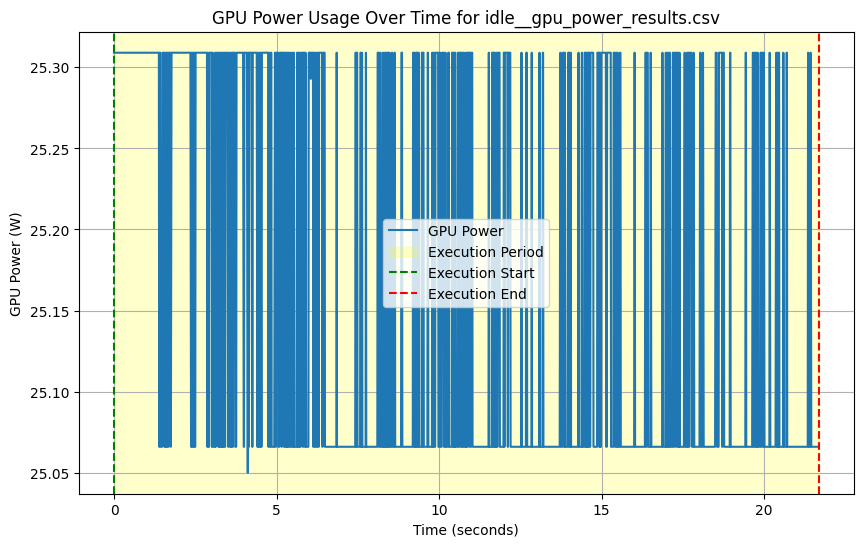

Start time: 0 -- End time: 21.673

Capturing idle energy consumed for same duration...
... Complete.
Code execution duration: 21.67 seconds
Total GPU energy consumption for idle__gpu_power_results.csv:
  0.000151 kWh
  0.1515 Wh
  545.23 J
Average GPU power: 25.16 W
Total Energy During Exe Runtime:   545.23 J
----------------------------------------------------------------------------------------------------------------------------------------





----- STARTING LLM CONTEXT BUILDING WITH SELF-PROMPTING -----


GPU Memory Status:
 GPU 0: 114 MiB used, 16269 MiB free, 16384 MiB total
 GPU 1: 114 MiB used, 16269 MiB free, 16384 MiB total

--> ... prompt LLM to summarize context knowledge.
**Summary of Key Relevant Points for Refactoring CUDA C++ Code to Improve Energy Efficiency:**

1. **Minimize Data Transfer Between Host and Device (High Priority):**
   - **Reduce Host-Device Communication:** Data transfers between the CPU (host) and GPU (device) consume significant power. Minimizing t

**Summary of Key Relevant Points for Refactoring CUDA C++ Code to Improve Energy Efficiency:**

1. **Minimize Data Transfer Between Host and Device (High Priority):**
   - **Reduce Host-Device Communication:** Data transfers between the CPU (host) and GPU (device) consume significant power. Minimizing these transfers reduces energy consumption.
   - **Process Data Entirely on the Device:** Create and manipulate intermediate data structures in device memory. Avoid transferring them back to the host unless necessary.
   - **Batch Transfers:** If data transfer is required, batch multiple small transfers into larger ones to reduce overhead and energy usage.
   - **Use Page-Locked (Pinned) Memory:** Utilizing pinned memory for data transfers achieves higher bandwidth and reduces power consumption due to more efficient data movement.

2. **Optimize Memory Access Patterns (High Priority):**
   - **Prefer Shared Memory Over Global Memory:** Accessing global memory is energy-intensive due to higher latency and power usage. Use shared memory for frequently accessed data to reduce energy consumption.
   - **Efficient Use of Memory Hierarchy:** Utilize registers, shared memory, and constant memory effectively. Organize data access patterns to take advantage of the faster, lower-power memory spaces.

3. **Maximize Occupancy to Hide Latency (Medium Priority):**
   - **Maintain Sufficient Active Threads:** Ensure enough active threads per multiprocessor to hide memory latency, allowing the GPU to work efficiently and consume less energy.
   - **Optimal Thread Block Size:** Use thread block sizes that are multiples of 32 (the warp size) to maximize hardware efficiency and reduce power consumption.

4. **Avoid Divergent Warps (High Priority):**
   - **Uniform Execution Paths:** Ensure threads within the same warp follow the same execution path to prevent warp divergence, which leads to inefficient execution and increased energy usage.
   - **Optimize Control Flow:** Structure conditionals and loops to minimize divergence. When control flow depends on thread indices, align conditions with warp boundaries.

5. **Utilize Fast Math Functions Where Appropriate (Medium Priority):**
   - **Use Fast Math Library Functions:** Replace regular math functions with their faster counterparts (e.g., `__sinf()`, `__expf()`) when high precision is not critical. This reduces execution time and energy consumption.
   - **Select Specialized Functions:** Choose specialized math functions (e.g., `exp2()`, `exp10()`, `sinpi()`) over general ones like `pow()` for performance and energy efficiency gains.

6. **Efficient Synchronization and Memory Operations:**
   - **Use Lightweight Synchronization:** Employ `__syncthreads()` within thread blocks for efficient synchronization without excessive energy overhead.
   - **Leverage Asynchronous Operations:** Utilize asynchronous memory copies and kernel launches to overlap data transfers with computation, reducing idle times and energy usage.
   - **Asynchronous Data Transfers:** Use `cudaMemcpyAsync()` and streams to perform data transfers without stalling the CPU or GPU.

7. **Optimize Arithmetic Operations (Low Priority):**
   - **Use Bitwise Operations:** Replace expensive integer division and modulo operations with bitwise shifts and masks when operands are powers of two to save energy.
   - **Prefer Signed Integers for Loop Counters:** Signed integers allow the compiler to optimize loops more aggressively, potentially reducing instruction count and energy consumption.

8. **Reduce Register and Memory Pressure:**
   - **Limit Register Usage:** Excessive use of registers can cause spilling to local memory (which resides in global memory), leading to higher energy consumption. Optimize kernel code to use fewer registers.
   - **Avoid Unnecessary Memory Accesses:** Eliminate redundant loads and stores by reusing data in registers or shared memory when possible.

9. **Consider Compute Capability and Hardware Features:**
   - **Target Appropriate Hardware Features:** Tailor optimizations to the GPU's compute capability, taking advantage of specific hardware features that improve energy efficiency.
   - **Utilize Thread Block Clusters:** On supported architectures, leverage thread block clusters for efficient inter-block communication and synchronization.

10. **Avoid Automatic Type Conversions (Low Priority):**
    - **Consistent Data Types:** Use consistent data types to prevent the compiler from inserting implicit conversions, which add extra instructions and consume more energy.
    - **Use Single-Precision Constants:** In single-precision computations, define floating-point constants with an `f` suffix to avoid unnecessary double-precision operations.

11. **Facilitate Compiler Optimizations:**
    - **Enable Loop Unrolling:** Use `#pragma unroll` to guide the compiler in unrolling loops, reducing overhead and improving energy efficiency.
    - **Simplify Control Structures:** Write code that allows the compiler to apply branch predication and other optimizations, minimizing energy-intensive branching.

12. **Minimize Idle GPU Time:**
    - **Overlap Computation and Communication:** Use streams and asynchronous operations to overlap data transfers with kernel execution, keeping the GPU busy and reducing energy wasted on idle periods.
    - **Efficient Kernel Launches:** Combine small kernels when possible or ensure each kernel performs sufficient work to justify launch overhead.

13. **Code Refactoring for Energy Efficiency:**
    - **Profile and Identify Hotspots:** Use profiling tools to find energy-intensive parts of the code and focus optimization efforts there.
    - **Algorithmic Optimizations:** Implement more efficient algorithms that reduce computational complexity and memory accesses, resulting in lower energy consumption.

By applying these key practices when refactoring CUDA C++ code, we can enhance energy efficiency by reducing both GPU and CPU power consumption without compromising the original functionality of the code.

GPU Memory Status:
 GPU 0: 114 MiB used, 16269 MiB free, 16384 MiB total
 GPU 1: 114 MiB used, 16269 MiB free, 16384 MiB total

--> ... prompt LLM to describe the source code.
The provided CUDA C++ code is a GPU-accelerated solver for the two-dimensional (2D) lid-driven cavity flow problem using the finite difference method. It numerically solves the incompressible, isothermal Navier–Stokes equations for a square cavity. The code is structured to leverage the parallel computing capabilities of GPUs via CUDA, aiming to enhance computational efficiency for this fluid dynamics simulation.

**Overview of the Problem:**

- **Lid-Driven Cavity Flow:** This is a classical problem in fluid mechanics where a fluid inside a square cavity is set into motion by moving one boundary (the lid) while the other boundaries remain stationary.
- **Incompressible Navier–Stokes Equations:** The code solves these equations, which govern the motion of incompressible fluids.
- **Finite Difference Method:** Spa

The provided CUDA C++ code is a GPU-accelerated solver for the two-dimensional (2D) lid-driven cavity flow problem using the finite difference method. It numerically solves the incompressible, isothermal Navier–Stokes equations for a square cavity. The code is structured to leverage the parallel computing capabilities of GPUs via CUDA, aiming to enhance computational efficiency for this fluid dynamics simulation.

**Overview of the Problem:**

- **Lid-Driven Cavity Flow:** This is a classical problem in fluid mechanics where a fluid inside a square cavity is set into motion by moving one boundary (the lid) while the other boundaries remain stationary.
- **Incompressible Navier–Stokes Equations:** The code solves these equations, which govern the motion of incompressible fluids.
- **Finite Difference Method:** Spatial discretization is achieved using finite differences on a uniform grid.
- **Red-Black Gauss-Seidel with Successive Over-Relaxation (SOR):** An iterative method is used to solve the pressure Poisson equation, which is part of enforcing incompressibility.

**Major Components of the Code:**

1. **Constants and Parameters:**

   - **Grid Size (`NUM`):** The number of cells along one side of the square domain (default is 512). Total cells are `NUM × NUM`.
   - **Physical Constants:**
     - **Reynolds Number (`Re_num`):** Controls the viscous effects in the flow (default is 1000.0).
     - **SOR Relaxation Parameter (`omega`):** Used in the SOR iterative method for accelerating convergence (default is 1.7).
     - **Discretization Mix Parameter (`mix_param`):** Balances central and upwind differencing schemes (default is 0.9).
     - **Time Step Safety Factor (`tau`):** Ensures stability in time-stepping (default is 0.5).
     - **Domain Size (`xLength`, `yLength`):** Physical dimensions of the square domain (normalized to 1.0).

2. **Mesh Parameters:**

   - **Cell Sizes (`dx`, `dy`):** Determined by dividing the domain lengths by the number of cells (`NUM`).

3. **Macros for Indexing Arrays:**

   - **Velocity Fields (`u`, `v`):** Macros map 2D indices to 1D array positions for the velocity components in the x and y directions, respectively.
   - **Auxiliary Variables (`F`, `G`):** Represent tentative velocities used in the projection method to enforce incompressibility.
   - **Pressure Fields (`pres_red`, `pres_black`):** Pressure values are stored separately for red and black cells to facilitate the Red-Black Gauss-Seidel method.

4. **Data Structures:**

   - **Arrays:**
     - **`u`, `v`:** Velocity components in x and y directions. Size: `(NUM + 2) × (NUM + 2)` to account for boundary cells.
     - **`F`, `G`:** Tentative velocities computed from the discretized momentum equations. Same size as `u`, `v`.
     - **`pres_red`, `pres_black`:** Pressure values for red and black cells. Size: `((NUM / 2) + 2) × (NUM + 2)` due to the checkerboard pattern.
     - **`res`:** Residuals array for convergence checking of the pressure solver.
     - **`max_u_arr`, `max_v_arr`:** Arrays to store maximum velocity magnitudes for adaptive time-stepping calculation.
     - **`pres_sum`:** Used for computing the L2 norm of the pressure field for normalization.

5. **Functions and Kernels:**

   **Host Function:**

   - **`set_BCs_host(Real* u, Real* v)`:** Sets initial boundary conditions for the velocity fields on the host (CPU).
     - **Lid Velocity:** At the top boundary (`y = H`), the horizontal velocity `u` is set to a constant (implying the lid is moving), and the vertical velocity `v` is zero.
     - **No-slip Walls:** At the other boundaries (`x = 0` and `x = L`, `y = 0`), both `u` and `v` are set to satisfy the no-slip condition (zero velocity).

   **Device Kernels:**

   - **`set_BCs(Real* u, Real* v)`:** A CUDA kernel version of `set_BCs_host` for updating boundary conditions during simulation.
   - **`calculate_F(const Real dt, const Real* u, const Real* v, Real* F)`:** Computes the tentative velocity `F` for the `u` component using discretized momentum equations.
     - **Convection and Diffusion Terms:** Calculates the convective and viscous terms using finite differences.
     - **Mixing Parameter (`mix_param`):** Adjusts the discretization between central and upwind differencing to stabilize the solution.
   - **`calculate_G(const Real dt, const Real* u, const Real* v, Real* G)`:** Similar to `calculate_F`, but computes the tentative velocity `G` for the `v` component.
   - **`sum_pressure(const Real* pres_red, const Real* pres_black, Real* pres_sum)`:** Computes the sum of squared pressure values across the domain for normalization in convergence checking.
     - **Reduction Operation:** Uses shared memory to perform parallel reduction within each block.
   - **`set_horz_pres_BCs(Real* pres_red, Real* pres_black)`:** Sets horizontal (top and bottom) boundary conditions for the pressure field.
   - **`set_vert_pres_BCs(Real* pres_red, Real* pres_black)`:** Sets vertical (left and right) boundary conditions for the pressure field.
   - **`red_kernel(const Real dt, const Real* F, const Real* G, const Real* pres_black, Real* pres_red)`:** Updates pressure at red cells using the SOR iterative method.
     - **Pressure Poisson Equation:** Solves for pressure corrections to enforce the divergence-free condition (incompressibility).
   - **`black_kernel(const Real dt, const Real* F, const Real* G, const Real* pres_red, Real* pres_black)`:** Similar to `red_kernel`, but updates pressure at black cells.
   - **`calc_residual(const Real dt, const Real* F, const Real* G, const Real* pres_red, const Real* pres_black, Real* res_array)`:** Computes the residuals of the pressure Poisson equation to check for convergence.
     - **Convergence Criterion:** Based on the L2 norm of the residuals normalized by the initial pressure norm.
   - **`calculate_u(const Real dt, const Real* F, const Real* pres_red, const Real* pres_black, Real* u, Real* max_u)`:** Updates the velocity component `u` using the corrected pressure field and computes the maximum `u` for adaptive time-stepping.
   - **`calculate_v(const Real dt, const Real* G, const Real* pres_red, const Real* pres_black, Real* v, Real* max_v)`:** Similar to `calculate_u`, but for the `v` component.

6. **Main Function (`int main(int argc, char *argv[])`):**

   - **Initialization:**
     - **Allocate Memory:** Allocates host memory for all arrays and initializes them.
     - **Set Initial Boundary Conditions:** Calls `set_BCs_host` to initialize velocity fields.
     - **Compute Initial Maximum Velocities:** Determines `max_u` and `max_v` for time-stepping calculations.
   - **Device Memory Allocation and Data Transfer:**
     - **Allocate Device Memory:** Uses `cudaMalloc` to allocate GPU memory for all required arrays.
     - **Copy Data to Device:** Transfers initialized arrays to the device using `cudaMemcpy`.
   - **Simulation Loop:**
     - **Time-Stepping Loop:** Advances the solution in time until the specified end time (`time_end`) is reached.
     - **Compute Time Step (`dt`):** Based on the CFL condition and viscosity constraints to ensure stability.
     - **Compute Tentative Velocities:**
       - **`calculate_F` and `calculate_G`:** Compute the tentative velocities `F` and `G`.
     - **Pressure Solver Iteration:**
       - **Initialize Pressure Norm:** Uses `sum_pressure` to compute the initial pressure norm for normalization.
       - **Iterative Solver Loop:** Updates pressure using `red_kernel` and `black_kernel` until convergence criteria (`tol`) are met or maximum iterations (`it_max`) are reached.
       - **Convergence Check:** Uses `calc_residual` to compute the residuals and checks against the tolerance.
     - **Velocity Correction:**
       - **`calculate_u` and `calculate_v`:** Update the velocity fields using the corrected pressure and compute maximum velocities.
     - **Boundary Condition Update:** Calls `set_BCs` to update velocity boundary conditions on the device.
     - **Time Update:** Increments the simulation time by `dt`.
   - **Post-Simulation Processing:**
     - **Copy Results to Host:** Transfers the final velocity and pressure fields back to the host.
     - **Output Results:** Writes the velocity field to a file (`velocity_gpu.dat`) for visualization or analysis.
   - **Cleanup:**
     - **Free Device and Host Memory:** Releases all allocated memory to prevent leaks.

**Algorithm Summary:**

- **Discretization:** The domain is discretized into a uniform grid. Spatial derivatives are approximated using finite differences.
- **Time Integration:**
  - **Explicit Scheme:** Tentative velocities (`F` and `G`) are computed explicitly based on the current velocity fields.
  - **Adaptive Time-Stepping:** The time step (`dt`) is adjusted dynamically based on the maximum velocities and a safety factor to satisfy stability criteria.
- **Pressure Correction:**
  - **Projection Method:** The pressure Poisson equation is solved iteratively to correct the velocity field, ensuring mass conservation (divergence-free).
  - **Red-Black Gauss-Seidel with SOR:** This method enhances convergence speed by updating pressure values in a checkerboard pattern and applying over-relaxation.
- **Parallelization:**
  - **CUDA Kernels:** Computationally intensive tasks are parallelized using CUDA kernels to distribute workload across GPU threads.
  - **Shared Memory and Synchronization:** Uses shared memory for efficient data access within blocks and synchronization primitives like `__syncthreads` for reduction operations.
  - **Block and Grid Configuration:** Carefully configured to optimize occupancy and performance on the GPU.

**Key Variables and Their Roles:**

- **`u`, `v`:** Velocity components in the x and y directions, representing the primary solution fields.
- **`F`, `G`:** Tentative velocity fields used in the fractional step method before pressure correction.
- **`pres_red`, `pres_black`:** Pressure fields split into red and black cells to facilitate the iterative solver.
- **`dt`:** Time step size, dynamically adjusted to ensure numerical stability.
- **`res`:** Residuals array used to determine convergence of the pressure solver.
- **`max_u`, `max_v`:** Maximum values of velocity components used to compute the Courant–Friedrichs–Lewy (CFL) condition for time-stepping.

**Boundary Conditions:**

- **No-Slip Walls:** Velocity is set to zero at stationary boundaries.
- **Moving Lid:** The top boundary (`y = H`) has a specified horizontal velocity (typically set to a constant value representing the lid's motion).
- **Pressure Boundary Conditions:** Pressure gradients are adjusted at the boundaries to prevent artificial pressure buildup and ensure a realistic flow field.

**Numerical Methods and Stability:**

- **Finite Difference Method:** Second-order accurate central differences are used for spatial derivatives.
- **Upwind Differencing:** The `mix_param` allows blending between central and upwind schemes to enhance stability in the presence of high convection.
- **SOR Iteration:** Over-relaxation accelerates convergence in the iterative pressure solver.
- **Adaptive Time-Stepping:** Adjusts `dt` based on the flow field to maintain stability without unnecessarily small time steps.

**Performance Considerations:**

- **Parallel Computation:** Leveraging GPU parallelism significantly reduces computation time for large grids.
- **Memory Access Patterns:**
  - **Coalesced Access:** Data structures and access patterns are designed to optimize memory bandwidth by ensuring coalesced memory accesses.
  - **Shared Memory Usage:** Reduces global memory accesses by placing frequently accessed data in shared memory.
- **Synchronization:** Proper synchronization within CUDA kernels ensures data consistency and correct reduction operations.

**Conclusion:**

The code efficiently solves the 2D lid-driven cavity flow problem by combining numerical methods with GPU acceleration. It demonstrates key techniques in computational fluid dynamics (CFD) simulations, such as:

- Implementation of boundary conditions.
- Use of iterative solvers for pressure correction.
- Handling of stability through time-stepping and discretization schemes.
- Optimization for parallel architectures to achieve significant performance gains.

This code serves as a practical example of applying computational techniques to solve complex fluid dynamics problems while utilizing modern GPU hardware for enhanced computational efficiency.

GPU Memory Status:
 GPU 0: 114 MiB used, 16269 MiB free, 16384 MiB total
 GPU 1: 114 MiB used, 16269 MiB free, 16384 MiB total


----- REVIEW THE INSTRUCTIONS TASK PROMPT  (prompt with code, token count: 20631): 



[BACKGROUND KNOWLEDGE: CUDA C++ PROGRAMMING BEST PRACTICES] Chapter 5. Programming Model This chapter introduces the main concepts behind the CUDA programming model by outlining how they are exposed in C++. An extensive description of CUDA C++ is given in Programming Interface. Full code for the vector addition example used in this chapter and the next can be found in the vectorAdd CUDA sample. 5. 1. Kernels CUDA C++ extends C++ by allowing the programmer to define C++ functions, called kernels, that, when called, are executed N times in parallel by N different CUDA threads, as opposed to only once like regular C++ functions. A kernel is defined using the __global__ declaration specifier and the number of CUDA threads that execute that kernel for a given kernel call is spec

**Summary of Identified Inefficiencies:**

1. **Excessive Host-Device Data Transfers:**
   - The code frequently copies data between the host and device within the time-stepping loop, particularly after computing residuals and maximum velocities (`cudaMemcpy` of `res_d`, `max_u_d`, and `max_v_d` to host memory).
   - These frequent transfers increase energy consumption due to high data movement between CPU and GPU.

2. **Synchronous Operations and Synchronizations:**
   - The code performs `cudaDeviceSynchronize()` calls unnecessarily after kernel launches, preventing overlap of computation and memory operations.
   - Synchronizations within kernels may be excessive or could potentially be optimized to reduce idle GPU cycles.

3. **Underutilization of Asynchronous Operations:**
   - The code does not utilize asynchronous memory copies (`cudaMemcpyAsync`) or CUDA streams to overlap data transfers with computation.
   - Lack of concurrency leads to idle periods on both CPU and GPU, increasing energy consumption.

4. **Inefficient Memory Access Patterns:**
   - Potential non-coalesced global memory accesses due to indirection in array indexing, which can be optimized for better memory bandwidth utilization.
   - Use of global memory where shared memory could be utilized for data that is repeatedly accessed within kernels.

5. **Warp Divergence:**
   - Conditional statements inside kernels dependent on thread indices (`if` statements) may cause warp divergence.
   - Divergent warps execute sequentially rather than in parallel, leading to inefficient GPU utilization.

6. **Non-optimal Thread Block Size and Occupancy:**
   - The thread block size is fixed at 128 threads, which may not be optimal for the GPU architecture (optimal sizes are typically multiples of 32 but may vary).
   - Suboptimal occupancy can lead to insufficient hiding of memory latency and lower energy efficiency.

7. **Redundant Computations:**
   - Recalculation of constant expressions within kernels (e.g., `TWO / (dx * dx)`) instead of precomputing them.
   - Duplicate computations in calculating maximum velocities and residuals.

8. **Inefficient Use of Math Functions:**
   - Use of expensive standard math functions like `sqrt`, `fabs`, and `fmax` without using their faster counterparts.
   - Potential for replacing standard functions with intrinsic fast math functions where higher precision is not necessary.

9. **Not Using Pinned Memory:**
   - Memory allocations on the host are standard (`calloc`), not page-locked (pinned), resulting in lower bandwidth during data transfers.

10. **Inefficient Loop Constructs:**
    - Use of nested loops with potential for uncoalesced accesses and non-optimal compiler optimizations.
    - Loop counters and indices declared as signed integers but used in contexts where unsigned integers may be more appropriate.

**Refactoring Plan to Improve Energy Efficiency:**

To enhance energy efficiency by reducing both GPU and CPU power consumption without compromising functionality, the following optimizations are proposed, aligned with the best practices from the background knowledge:

1. **Minimize Host-Device Data Transfers (High Priority):**
   - **Strategy:**
     - **Keep Computations on the Device:** Perform convergence checks and maximum velocity calculations entirely on the GPU to avoid frequent data transfers.
     - **Use Device-side Reduction Kernels:** Implement reduction operations (e.g., summing residuals, finding maximum velocities) fully on the GPU.
   - **Implementation:**
     - **Residual Calculation:** Modify `calc_residual` to perform a complete reduction and store the result in device memory. Utilize atomic operations or parallel reduction techniques within a single kernel launch.
     - **Maximum Velocity Calculation:** Combine `calculate_u` and `calculate_v` with reduction operations to find the maximum velocities on the GPU.
   - **Best Practices Applied:**
     - *"Minimize data transfer between the host and the device..."*
     - *"Intermediate data structures should be created in device memory..."*

2. **Utilize Asynchronous Memory Operations and Overlap with Computation (High Priority):**
   - **Strategy:**
     - **Use CUDA Streams and `cudaMemcpyAsync`:** Overlap data transfers with kernel execution to keep both CPU and GPU busy.
     - **Avoid Unnecessary Synchronizations:** Remove `cudaDeviceSynchronize()` calls where possible to allow for concurrency.
   - **Implementation:**
     - **Asynchronous Transfers:** Replace `cudaMemcpy` with `cudaMemcpyAsync` for data transfers that must occur, assigning them to non-default streams.
     - **Stream Management:** Assign kernels and memory operations to streams that allow overlap of computations and data transfers.
   - **Best Practices Applied:**
     - *"Use asynchronous operations to overlap data transfers with computation..."*
     - *"Minimize idle GPU time by overlapping computation and communication."*

3. **Use Pinned Memory for Data Transfers (High Priority):**
   - **Strategy:**
     - **Allocate Host Memory as Pinned Memory:** Use `cudaHostAlloc` to allocate pinned host memory for faster data transfers.
   - **Implementation:**
     - **Replace `calloc` with `cudaHostAlloc`:** Allocate host-side arrays (`u`, `v`, `F`, `G`, etc.) using `cudaHostAlloc` with the `cudaHostAllocDefault` flag.
   - **Best Practices Applied:**
     - *"Use page-locked (pinned) memory for higher bandwidth between the host and the device."*

4. **Optimize Memory Access Patterns (High Priority):**
   - **Strategy:**
     - **Ensure Coalesced Memory Accesses:** Restructure data layouts and access patterns to allow for coalesced global memory accesses.
     - **Leverage Shared Memory:** Use shared memory for data that is reused within threads of a block to reduce global memory accesses.
   - **Implementation:**
     - **Data Alignment:** Align arrays in memory and ensure that threads access contiguous memory locations.
     - **Shared Memory Usage:** Identify data accessed multiple times by the same thread block and load it into shared memory.
   - **Best Practices Applied:**
     - *"Prefer shared memory access where possible to minimize the use of global memory."*
     - *"Organize data access patterns to take advantage of faster, lower-power memory spaces."*

5. **Avoid Warp Divergence (High Priority):**
   - **Strategy:**
     - **Refactor Conditional Statements:** Modify control flow in kernels to minimize divergence within warps.
     - **Align Conditionals with Warp Boundaries:** When conditionals are necessary, align them with warp boundaries to prevent threads within the same warp from diverging.
   - **Implementation:**
     - **Rewriting Kernels:** Analyze kernels like `calculate_u` and `calculate_v` to reduce conditional branching based on thread indices.
     - **Use Predication:** Allow the compiler to use predication by simplifying conditionals and possibly unrolling small loops.
   - **Best Practices Applied:**
     - *"Avoid different execution paths within the same warp."*
     - *"To obtain best performance... the controlling condition should be written to minimize the number of divergent warps."*

6. **Optimize Kernel Launch Parameters and Occupancy (Medium Priority):**
   - **Strategy:**
     - **Adjust Block Sizes:** Experiment with thread block sizes (multiples of 32 up to 256 or 512) to find the optimal size for the target GPU architecture.
     - **Increase Occupancy:** Ensure sufficient active warps to hide memory latency and improve energy efficiency.
   - **Implementation:**
     - **Occupancy Calculator:** Use NVIDIA's Occupancy Calculator to determine the optimal block size for the GPU in use.
     - **Dynamic Block Sizes:** Modify `BLOCK_SIZE` to the optimal value and adjust grids accordingly.
   - **Best Practices Applied:**
     - *"Maintain sufficient numbers of active threads per multiprocessor (i.e., sufficient occupancy)."*
     - *"The number of threads per block should be a multiple of 32 threads..."*

7. **Reduce Redundant Computations (Medium Priority):**
   - **Strategy:**
     - **Precompute Constants:** Calculate expressions like `(TWO / (dx * dx))` outside kernels and pass them as parameters.
     - **Eliminate Duplicate Calculations:** Identify and remove any redundant computations within kernels.
   - **Implementation:**
     - **Kernel Parameters:** Add additional parameters to kernels for precomputed constants.
     - **Code Refactoring:** Refactor code within kernels to store intermediate results and reuse them.
   - **Best Practices Applied:**
     - *"Avoid redundant calculations by reusing data in registers or shared memory."*
     - *"Facilitate compiler optimizations by simplifying control structures."*

8. **Use Fast Math Functions (Medium Priority):**
   - **Strategy:**
     - **Replace Standard Math Functions:** Use intrinsic fast math functions (e.g., `__fsqrt_rn`, `__fabsf`, `__fmaxf`) where high precision is not critical.
     - **Enable Fast Math Compilation:** Compile with the `-use_fast_math` flag to replace math functions with their faster counterparts.
   - **Implementation:**
     - **Modify Function Calls:** Replace calls to `sqrt`, `fabs`, and `fmax` with `__fsqrt_rn`, `__fabsf`, and `__fmaxf` or use the `fast_math` namespace.
     - **Compilation Flags:** Add `-use_fast_math` to the NVCC compiler flags in the build process.
   - **Best Practices Applied:**
     - *"Use the fast math library whenever speed trumps precision."*
     - *"Prefer faster, more specialized math functions over slower, more general ones when possible."*

9. **Use Asynchronous Memory Copies and Streams (Medium Priority):**
   - **Strategy:**
     - **Overlap Data Transfers with Computation:** Use CUDA streams to perform data transfers concurrently with kernel execution.
     - **Asynchronous Kernels:** Ensure kernels are launched in streams that allow for overlapping operations.
   - **Implementation:**
     - **Create CUDA Streams:** Define one or more CUDA streams for asynchronous operations.
     - **Modify Data Transfers and Kernel Launches:** Use `cudaMemcpyAsync` and specify streams in kernel launches.
   - **Best Practices Applied:**
     - *"Asynchronous data transfers and kernel launches to overlap data transfers with computation..."*
     - *"Use asynchronous operations to keep the GPU busy and reduce energy wasted on idle periods."*

10. **Optimize Synchronizations and Reductions (Medium Priority):**
    - **Strategy:**
      - **Use Cooperative Groups for Synchronization:** Employ CUDA's cooperative groups to synchronize threads more efficiently within kernels.
      - **Optimize Reduction Operations:** Implement efficient parallel reduction patterns to minimize synchronization overhead.
    - **Implementation:**
      - **Cooperative Groups API:** Utilize `cooperative_groups` to manage synchronization within thread blocks or warps.
      - **Efficient Reductions:** Apply warp-level primitives and avoid unnecessary `__syncthreads()` calls.
    - **Best Practices Applied:**
      - *"Use lightweight synchronization primitives..."*
      - *"Efficient synchronization and memory operations to reduce idle times and energy usage."*

11. **Batch Small Kernels and Combine Operations (Low Priority):**
    - **Strategy:**
      - **Kernel Fusion:** Combine small kernels that operate on the same data into a single kernel to reduce launch overhead.
    - **Implementation:**
      - **Merge Kernels:** For example, combine `calculate_F` and `calculate_G` into a single kernel if possible.
    - **Best Practices Applied:**
      - *"Efficient kernel launches: Combine small kernels when possible..."*
      - *"Reduce kernel launch overhead for improved energy efficiency."*

12. **Prefer Signed Integers for Loop Counters (Low Medium Priority):**
    - **Strategy:**
      - **Use Signed Loop Counters:** Declare loop counters as signed integers to enable better compiler optimizations.
    - **Implementation:**
      - **Modify Declarations:** Ensure all loop counters are declared as `int` instead of `unsigned int`.
    - **Best Practices Applied:**
      - *"Use signed integers rather than unsigned integers as loop counters."*

13. **Facilitate Compiler Optimizations (Low Priority):**
    - **Strategy:**
      - **Use Compiler Directives:** Employ `#pragma unroll` to encourage loop unrolling where beneficial.
      - **Simplify Control Structures:** Write code that is amenable to compiler optimizations like branch predication.
    - **Implementation:**
      - **Loop Unrolling:** Apply `#pragma unroll` to small loops inside kernels.
      - **Refactor Code:** Simplify conditional statements and loops in the code.
    - **Best Practices Applied:**
      - *"Enable loop unrolling to reduce overhead and improve energy efficiency."*
      - *"Facilitate compiler optimizations by simplifying control structures."*

**Expected Outcomes:**

By applying these optimizations, the refactored code should:

- **Reduce Energy Consumption:** Lower power usage by minimizing data transfers and improving parallel efficiency.
- **Improve Performance:** Achieve faster execution times due to reduced memory latency and better GPU utilization.
- **Maintain Functionality:** Ensure that the scientific accuracy and outcomes of the simulation remain unchanged.

**Next Steps:**

- **Implement the Refactoring Plan:** Systematically apply the proposed changes, testing each modification to verify correctness.
- **Profile and Benchmark:** Use profiling tools (e.g., NVIDIA Nsight Systems) to measure performance and energy consumption before and after refactoring.
- **Iterate and Optimize Further:** Based on profiling results, make additional adjustments to fine-tune performance and energy efficiency.

---

By strategically applying these best practices from the CUDA optimization guide, the refactored code will exhibit enhanced energy efficiency, reduced power consumption, and improved computational performance, all while preserving the original functionality of the lid-driven cavity flow simulation.



----- REVIEW THE REFACTORING PLAN PROMPT  (prompt with code, token count: 16655): 

**Summary of Identified Inefficiencies:**

1. **Excessive Host-Device Data Transfers:**
   - The code frequently copies data between the host and device within the time-stepping loop, particularly after computing residuals and maximum velocities (`cudaMemcpy` of `res_d`, `max_u_d`, and `max_v_d` to host memory).
   - These frequent transfers increase energy consumption due to high data movement between CPU and GPU.

2. **Synchronous Operations and Synchronizations:**
   - The code performs `cudaDeviceSynchronize()` calls unnecessarily after kernel launches, preventing overlap of computation and memory operations.
   - Synchronizations within kernels may be excessive or could potentially be optimized to reduce idle GPU cycles.

3. **Underutilization of Asynchronous Operations:**
   - The code does not utilize asynchronous memory copies (`cudaMemcpyAsync`) or CUDA streams to overlap data transfers with 

Waiting for the system to settle down...: 100%|████████████████████████████████████████████████████████| 10/10 [00:10<00:00,  1.00s/it]


Execute command: ['./lid-driven-cavity-cuda_main_ee_refactorcode_CUDA_exp02test_o1p_o1p_betterpower_withcontext_fewshots', '']

Problem size: 512 x 512 
Time = 0.000477, delt = 4.768372e-04, iter = 92522, res = 9.999751e-04
Time = 0.000954, delt = 4.768372e-04, iter = 79241, res = 9.999398e-04
Time = 0.001000, delt = 4.632568e-05, iter = 74825, res = 9.999417e-04

Total execution time of the iteration loop: 19.445288 (s)
GPU power data has been written to generated_CUDA_gpu_power_results.csv


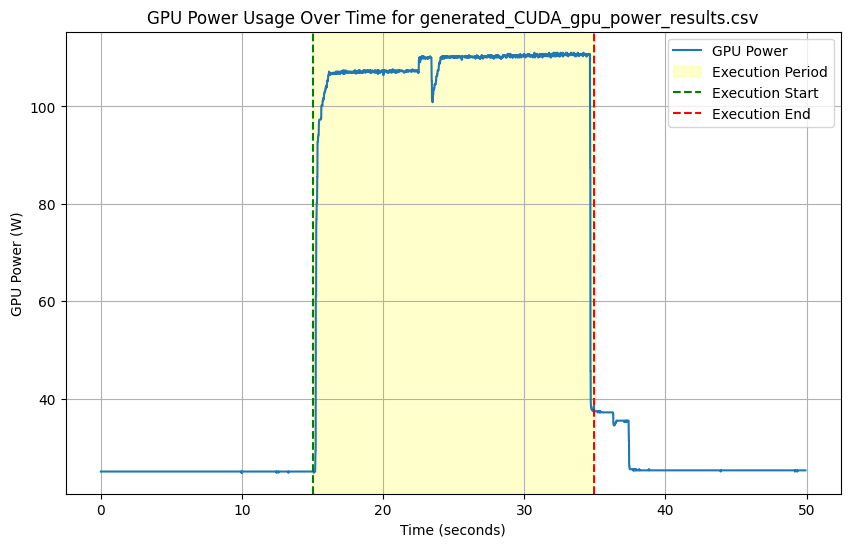

Start time: 15.0 -- End time: 34.928

Capturing idle energy consumed for same duration...
... Complete.
Code execution duration: 19.93 seconds
Total GPU energy consumption for generated_CUDA_gpu_power_results.csv:
  0.000593 kWh
  0.5930 Wh
  2134.88 J
Average GPU power: 107.16 W
Total Energy During Exe Runtime:   2134.88 J
----------------------------------------------------------------------------------------------------------------------------------------

Program executed successfully!
Power and Energy Feedback data: 
  sourcecode_total_energy_joules: 2290.73
  total_energy_joules_refactor: 2134.88
  sourcecode_ave_power: 105.75
  ave_power_refactor: 107.16
  runtime_sourcecode: 21.67
  runtime_refactored: 19.93


***** Generated refactored code is more energy efficient than source code! *****



-----CODE GENERATION COMPLETE-----

CODE GENERATION TIME: 6.52 minutes.

Self-correction count: 1

Metadata file: generated_codes/argo_gpto1preview/promptset_CUDA/metadata_lid-driven-cavit

In [3]:
prompts = PromptDictionary()

# Store the current home working directory (needed for code execution)
original_home_directory = os.getcwd()


# COLLECT THE EXPERIMENT CONFIGURATIONS
(
    app_folder_name, source_lang, target_lang, model, model_coder, num_ctx, num_ctx_coder,
    llm_source, use_context, context_knowledge_selection, code_compiler,
    code_compiler_kwds, yes_execute, exe_input_parameters, experiment,
    display_response, test_with_error, generate_test_case, power_measure, test_code_first, yes_power_feedback
) = experimental_setup()

# IMPORT CONTEXT KNOWLEDGE FOR TARGET PROGRAMMING LANGUAGE
input_context = "[BACKGROUND KNOWLEDGE: CUDA C++ PROGRAMMING BEST PRACTICES] " + prompts.get_codeknowledge("cuda") + "\n\n"  # [/END GENERAL CUDA PROGRAMMING CONTEXT]
input_context = input_context + "[BACKGROUND KNOWLEDGE: CUDA C++ OPTIMIZATION GUIDE] " + prompts.get_codeknowledge(str(context_knowledge_selection)) + "\n\n"  #  [/END CUDA OPTIMIZATION CONTEXT]


# DEFINE PROMPT TEMPLATES
system_prompt_selection_index = source_lang + "_ee"  # "_to_" + target_lang  # Select which prompt to use from the prompt dictionary
this_llm_system_prompt = prompts.get_system_prompt(str(system_prompt_selection_index))

coderefactor_prompt_selection_index = source_lang  # + "_to_" + target_lang  # Select which prompt to use from the prompt dictionary
this_llm_refactoredcode_prompt = prompts.get_code_ee_refactoring_prompt(str(coderefactor_prompt_selection_index))


# LOAD INPUT CODE TO TRANSLATE
input_code_folder = "HeCBench/" + app_folder_name + "/"
input_code_filename = app_folder_name + "-" + source_lang.lower() + "_main"
if source_lang == "OMP" or source_lang == "SYCL":
    input_code_extension = "cpp"
elif source_lang == "CUDA" or source_lang == "HIP":
    input_code_extension = "cu"
source_file_directory = "source_codes/" + input_code_folder
source_file_path = source_file_directory + input_code_filename + "." + input_code_extension
with open(source_file_path, 'r') as file:
    input_code = file.read()
file.close()

# SPECIFY OUTPUT CODE SAVE
directory = "generated_codes/" + llm_source + "_" + model.replace('/', '--') + "/promptset_" + str(coderefactor_prompt_selection_index)
file_name = input_code_filename + "_ee_refactorcode_" + source_lang + "_exp" + experiment


# CREATE METADATA RECORD CONTENT
meta_data_file = "***** EXPERIMENT CONFIGURATION SUMMARY *****\n"
meta_data_file += "\nApplication: " + app_folder_name
meta_data_file += "\n\nEE Refactoring: " + system_prompt_selection_index
# meta_data_file += "\nTranslate from: " + input_code_extension
# meta_data_file += "\nTranslate to: " + translated_code_extension
meta_data_file += "\n\nLLM Source: " + llm_source
meta_data_file += "\nModel: " + model
meta_data_file += "\nModel coder: " + model_coder
meta_data_file += "\nSystem Prompt Index: " + str(coderefactor_prompt_selection_index)
meta_data_file += "\nCode file template: " + directory + "/" + file_name
meta_data_file += "\n\nLLM System Prompt: " + "\n\n" + this_llm_system_prompt
meta_data_file += "\n\nLLM Prompt for Code Generation: " + "\n\n" + this_llm_refactoredcode_prompt
meta_data_file += "\n\nPower measurement: " + str(power_measure)

# Display metadata
print("\n" + meta_data_file + "\n")

print("\n\n" + color.BOLD + "***** BEGIN THE LASSI PIPELINE*****" + color.END + "\n\n")

# RUN PIPELINE
complete = lassi.pipeline.auto_code_llmgeneration_pipeline(
    prompts,
    this_llm_system_prompt,
    this_llm_refactoredcode_prompt,
    llm_source, 
    model,
    model_coder,
    num_ctx,
    num_ctx_coder,
    # arrayormatrix_size_range,
    # thread_count_range,
    use_context,
    input_context,
    input_code,
    # target_code,
    target_lang,
    input_code_extension,
    source_lang,
    code_compiler,
    code_compiler_kwds,
    directory,
    file_name,
    source_file_path,
    display_response,
    test_with_error,
    generate_test_case,
    yes_execute,
    exe_input_parameters,
    meta_data_file,
    power_measure, 
    test_code_first,
    yes_power_feedback
)

# Reset to original working directory
os.chdir(original_home_directory)

if complete:
    print("\n\n" + color.GREEN + color.BOLD + "***** LASSI PIPELINE COMPLETED *****\n\n" + color.END)
else:
    print("\n\n" + color.RED + color.BOLD + "***** LASSI PIPELINE FAILED TO COMPLETE *****\n\n" + color.END)

### TESTING ONLY

In [4]:
# energy = lassi.getpower.GetGPUpower.idlepower(10)
# print(energy)

# TESTING ONLY
# Names of the CSV files
'''
files = ['translated_code/ollama_codestral:22b-v0.1-q8_0/promptset_CUDA_to_OMP/generated_OMP_gpu_power_results.csv',
             #'./gpu_power_results_mtdv4.csv',
            ]
# Plot power usage and calculate energy
for file_name in files:
    inference_duration = lassi.getpower.plot_gpu_power(file_name)
    total_energy_joules, ave_power = lassi.getpower.calculate_total_energy(file_name)
    
    # Convert energy units
    total_energy_wh = total_energy_joules / 3600  # Convert from Joules to Watt-hours
    total_energy_kwh = total_energy_wh / 1000  # Convert from Watt-hours to Kilowatt-hours
    
    print(f"Inference duration: {inference_duration:.2f} seconds")
    print(f"Total GPU energy consumption for {file_name}:")
    print(f"  {total_energy_kwh:.6f} kWh")
    print(f"  {total_energy_wh:.4f} Wh")
    print(f"  {total_energy_joules:.2f} J")
    print(f"Average GPU power: {ave_power:.2f} W")
    print("----------------------------------------------------------------------------------------------------------------------------------------")
'''

# TESTING: code execution with power
'''
# exe_filename = "translated_code/ollama_codestral:22b-v0.1-q8_0/promptset_CUDA_to_OMP/atomicCost-cuda_main_translatecode_OMP_exp01test_power_withcontext"
exe_filename = "translated_code/input_codes/HeCBench/lid-driven-cavity/lid-driven-cavity-cuda_main"
# matrix-rotate-cuda_main_translatecode_OMP_exp01test_power_withcontext
input_parameters = [""]
power_measure = True
code_source = "target"
target_lang = "CUDA"

lassi.code_manager.execute_code(exe_filename, input_parameters, power_measure, code_source, target_lang)
'''

'\n# exe_filename = "translated_code/ollama_codestral:22b-v0.1-q8_0/promptset_CUDA_to_OMP/atomicCost-cuda_main_translatecode_OMP_exp01test_power_withcontext"\nexe_filename = "translated_code/input_codes/HeCBench/lid-driven-cavity/lid-driven-cavity-cuda_main"\n# matrix-rotate-cuda_main_translatecode_OMP_exp01test_power_withcontext\ninput_parameters = [""]\npower_measure = True\ncode_source = "target"\ntarget_lang = "CUDA"\n\nlassi.code_manager.execute_code(exe_filename, input_parameters, power_measure, code_source, target_lang)\n'